## 1. Introduction
### Pima Indians Diabetes Project🍫


- This project explores how machine learning can be used to predict diabetes using basic clinical measurements.
-Using the Pima Indians Diabetes dataset, several classification models were trained to identify whether a patient is likely to have diabetes.

- The goal of this project is to build a simple and reproducible machine learning pipeline that includes data cleaning, preprocessing, model training, and model evaluation on real medical data.

**Dataset**
Pima Indians Diabetes Dataset (UCI Machine Learning Repository)

768 patient records
8 clinical features: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age
Target variable:
0 = No diabetes
1 = Diabetes

**Methods**
The following steps were implemented in the project:
- Data cleaning and handling of medically invalid values
- Exploratory Data Analysis (EDA)
- Preprocessing pipeline (imputation and feature scaling)
- Training multiple classification models
- Model evaluation using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices
- Identifying the most important predictors of diabetes
- 
**Note**
All analysis, visualizations, and code implementations in this project were developed independently as part of a self‑directed learning project in computational biology.

### Research Questions
This project aims to answer the following questions:

- Can machine learning models predict diabetes using basic clinical measurements?
- Which physiological features are the most important predictors of diabetes?
- Which model performs better for this dataset: Logistic Regression or Random Forest?
- How well can the models identify true diabetes cases?

## 2. Importing Required Libraries
Import libraries for data handling, visualization, modeling, and evaluation


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Basic plot settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

# Model selection and evaluation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Preprocessing and Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


## 3. Load the dataset & define columns

In [3]:
# Load the dataset 

columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

df = pd.read_csv("../data/diabetes.csv")

# .. means go up one directory, from notebooks to the project root.
# data/ means enter the data folder.
# diabetes.csv is the file to load.


--------------------------------


## 4. Exploratory Data Analysis (EDA)
###  Data Inspection & Descriptive Statistics

4.1 Check number of rows and columns using df.shape :

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (768, 9)


- This dataset has 768 samples and 9 columns (8 features + target).


---






4.2 The first 5 rows to understand the dataset structure using df.head() :

In [5]:
print("\nFirst 5 rows:\n", df.head())  # Preview the data


First 5 rows:
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


---

4.3 Check Data Types & Missing Values  Using info():


In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


- The dataset contains 768 observations, eight predictor features, and one binary target variable (`Outcome`).
-  Although no explicit missing values are reported at this stage, some measurements are represented by zero values that require domain-specific investigation.

---

4.4 Class distribution

In [7]:
# Map numeric labels to meaningful class names
class_mapping = {
    0: "Non-Diabetic",
    1: "Diabetic"
}

# Calculate normalized class distribution
class_dist = df['Outcome'].value_counts(normalize=True).round(3)

# Apply mapping for readability
class_dist.index = class_dist.index.map(class_mapping)

print("\nClass distribution:")
print(class_dist)



Class distribution:
Outcome
Non-Diabetic    0.651
Diabetic        0.349
Name: proportion, dtype: float64


- The target distribution is `moderately imbalanced`: approximately 65.1% of observations belong to the non-diabetic class and 34.9% to the diabetic class.
- This difference should be considered when evaluating model performance.
- Accuracy alone may not adequately reflect the model's ability to identify diabetic cases, so recall, precision, F1-score, and ROC-AUC should also be examined.

---



4.5 Summary Statistics of Dataset Using df.describe()

In [8]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


- Zero values appear in `Glucose, BloodPressure, SkinThickness, Insulin, and BMI`.
- Zero values in Glucose, BloodPressure, and BMI are physiologically implausible.
- Zero values in SkinThickness and Insulin are treated as potentially missing or unrecorded measurements.
- Zero values in Pregnancies are valid and should be preserved.


These findings indicate that some values require further handling before model training.

---

## 5. Data Cleaning: Handling Invalid Zero Values

- Based on the findings from the exploratory analysis, zero values in the five selected measurement columns were converted to `NaN`.
- This allows missing measurements to be handled explicitly during preprocessing.
- Zero values in `Pregnancies` were preserved because they are valid observations.
- Imputation parameters will be learned within the training pipeline to prevent data leakage.

In [10]:
# Identify columns where zero values are invalid (medically impossible)
cols_with_invalid_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']


# Replace 0 with NaN (Not a Number) in these specific columns
# This prevents the model from treating missing data as actual physiological values
df[cols_with_invalid_zeros] = df[cols_with_invalid_zeros].replace(0, np.nan)


# Count and display the number of missing values (NaN) in each column
print("Number of missing values (NaN) per column:")
print(df.isnull().sum())


Number of missing values (NaN) per column:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


Statistical operations after data cleaning :

In [11]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


#### Summary Statistics After Cleaning

- After converting selected zero values to missing values, the observed counts differ across features.
- Insulin and SkinThickness have the highest levels of missingness, which may affect the reliability of subsequent analysis.
- The descriptive statistics now summarize the available non-missing observations.
- Missing values will be handled during model preprocessing rather than by deleting large numbers of rows.

#### missingness percentage


In [13]:

# Quantify missing values by feature.
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percent",
    ascending=False
)

display(missing_summary)


,Missing_Count,Missing_Percent
Insulin,374,48.70
SkinThickness,227,29.56
BloodPressure,35,4.56
BMI,11,1.43
Glucose,5,0.65
Pregnancies,0,0.00
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,0,0.00


- For this dataset, Insulin should show approximately 48.7% missingness, while SkinThickness should show approximately 29.6%.

-----------------------

## 6. Data Visualization

This section provides a visual and statistical overview of the dataset.

### 6.1 KDE (Kernel Density Estimate) Plot for Comparing 8 features in Diabetic vs. Healthy individuals

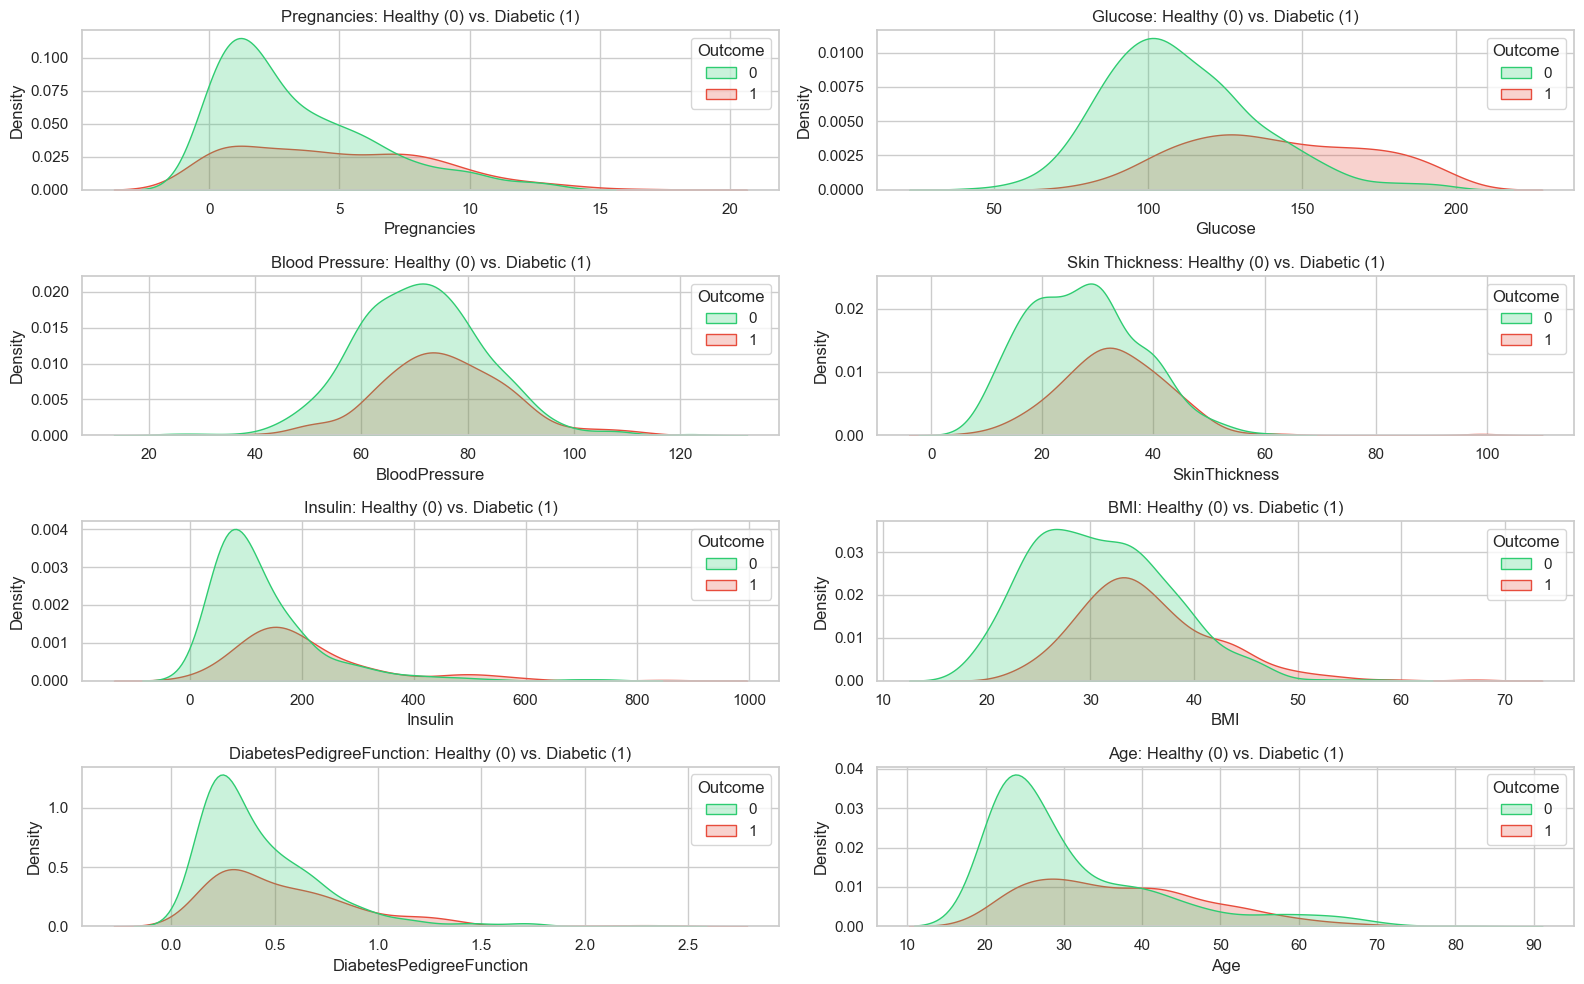

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(16, 10))

# Green for healthy & red for diabetic individuals
my_palette = ['#2ecc71', '#e74c3c']

# KDE Plot for Pregnancies
sns.kdeplot(data=df, x='Pregnancies', hue='Outcome', fill=True, ax=axes[0, 0], palette=my_palette)
axes[0, 0].set_title('Pregnancies: Healthy (0) vs. Diabetic (1)')

# KDE Plot for Glucose
sns.kdeplot(data=df, x='Glucose', hue='Outcome', fill=True, ax=axes[0, 1], palette=my_palette)
axes[0, 1].set_title('Glucose: Healthy (0) vs. Diabetic (1)')

# KDE Plot for BloodPressure 
sns.kdeplot(data=df, x='BloodPressure', hue='Outcome', fill=True, ax=axes[1, 0], palette=my_palette)
axes[1, 0].set_title('Blood Pressure: Healthy (0) vs. Diabetic (1)')

# KDE Plot for SkinThickness
sns.kdeplot(data=df, x='SkinThickness', hue='Outcome', fill=True, ax=axes[1, 1], palette=my_palette)
axes[1, 1].set_title('Skin Thickness: Healthy (0) vs. Diabetic (1)')

# KDE Plot for Insulin
sns.kdeplot(data=df, x='Insulin', hue='Outcome', fill=True, ax=axes[2, 0], palette=my_palette)
axes[2, 0].set_title('Insulin: Healthy (0) vs. Diabetic (1)')

# KDE Plot for BMI
sns.kdeplot(data=df, x='BMI', hue='Outcome', fill=True, ax=axes[2, 1], palette=my_palette)
axes[2, 1].set_title('BMI: Healthy (0) vs. Diabetic (1)')

# KDE Plot for DiabetesPedigreeFunction
sns.kdeplot(data=df, x='DiabetesPedigreeFunction', hue='Outcome', fill=True, ax=axes[3, 0], palette=my_palette)
axes[3, 0].set_title('DiabetesPedigreeFunction: Healthy (0) vs. Diabetic (1)')

# KDE Plot for Age
sns.kdeplot(data=df, x='Age', hue='Outcome', fill=True, ax=axes[3, 1], palette=my_palette)
axes[3, 1].set_title('Age: Healthy (0) vs. Diabetic (1)')



plt.tight_layout()
plt.show()



### Interpretation of KDE Plots

KDE plots compare the estimated distributions of each feature across the two outcome groups. Differences in curve locations, shapes, and overlap suggest potential associations with diabetes status, but they do not establish statistical significance or causation.

- **Pregnancies:** The distribution for Outcome = 1 is shifted toward higher values, suggesting an association between pregnancy count and diabetes status in this dataset.
- **Glucose:** The Outcome = 1 distribution is shifted toward higher glucose levels, making glucose a promising candidate predictor.
- **BloodPressure:** The distributions overlap considerably, suggesting limited separation between the outcome groups based on this feature alone.
- **SkinThickness:** The distributions overlap substantially, so the plot provides limited evidence of clear separation between the groups.
- **Insulin:** Both distributions are right-skewed, with considerable overlap and long upper tails. Differences should be interpreted cautiously because this feature has substantial missingness.
- **BMI:** The Outcome = 1 distribution is shifted toward higher BMI values, suggesting a potential association with diabetes status.
- **DiabetesPedigreeFunction:** The Outcome = 1 distribution appears somewhat shifted toward higher values, although the distributions overlap.
- **Age:** The Outcome = 1 distribution extends toward older ages, suggesting an association between age and diabetes status.

**Overall finding:** Glucose shows one of the clearest distributional differences between the two groups. Several other features also show potential associations, but their independent predictive value must be assessed through model evaluation. These plots are exploratory and do not establish causation or statistical significance.

---

### 6.2 Correlation Heatmap plot for Biological features

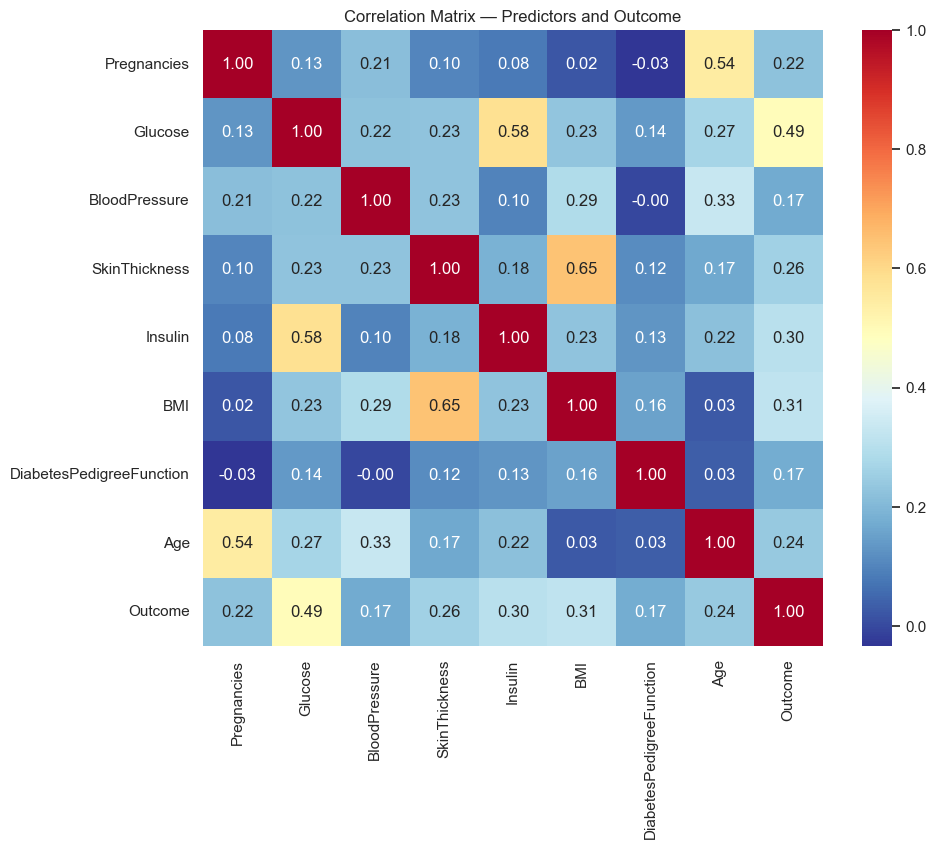

In [15]:
# Create correlation matrix for all features including Outcome
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r"
)

plt.title("Correlation Matrix — Predictors and Outcome")
plt.show()

### Interpretation of the Correlation Heatmap

The heatmap displays Pearson correlation coefficients, which measure the strength and direction of linear relationships between pairs of variables.

- **Glucose and Outcome (0.49):** Glucose has the strongest positive linear correlation with the target among the features shown. Higher glucose values tend to be associated with Outcome = 1.
- **BMI and Outcome (0.31):** BMI has a weaker positive correlation with the target.
- **Insulin and Outcome (0.30):** Insulin shows a positive correlation with the target, although missingness should be considered when interpreting this relationship.
- **SkinThickness and BMI (0.65):** These features have a moderately strong positive correlation, indicating that higher values tend to occur together.
- **Age and Pregnancies (0.54):** Older individuals tend to have higher pregnancy counts in this dataset.
- **BloodPressure and Outcome (0.17):** The linear correlation with the target is relatively weak.

- Glucose has the strongest observed linear association with the target in this heatmap. However, correlation alone does not establish causation or determine a feature's predictive importance. Model evaluation will help establish whether these variables contribute useful predictive information.


---


### 6.3 Histogram Plot of Glucose levels by diabetes status

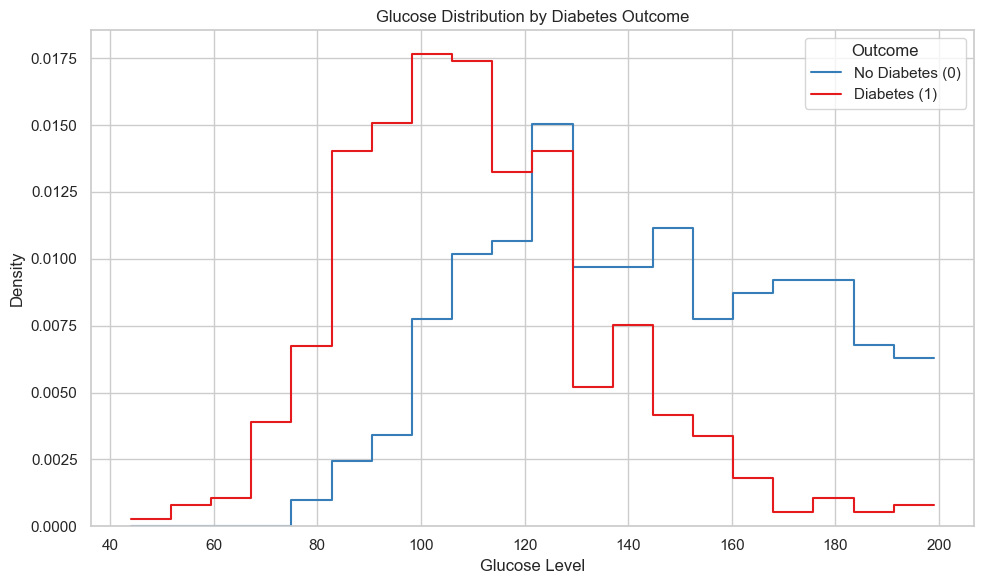

In [16]:
# Compare glucose distributions using normalized histograms
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Glucose",
    hue="Outcome",
    hue_order=[0, 1],
    bins=20,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    palette="Set1"
)

plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Glucose Level")
plt.ylabel("Density")
plt.legend(
    title="Outcome",
    labels=["No Diabetes (0)", "Diabetes (1)"]
)
plt.tight_layout()
plt.show()


### Interpretation of Glucose Distribution

- The glucose distributions differ between the two outcome groups.
- Observations with Outcome = 1 tend to have higher glucose levels, although the distributions overlap.
- This pattern suggests that glucose may be a useful predictor of diabetes status.
- However, the histogram alone does not establish statistical significance, causation, or the feature's independent predictive contribution.

-------------------------------

### 6.4 Scatter Plot for seeing how Age and Glucose are related to Diabetes


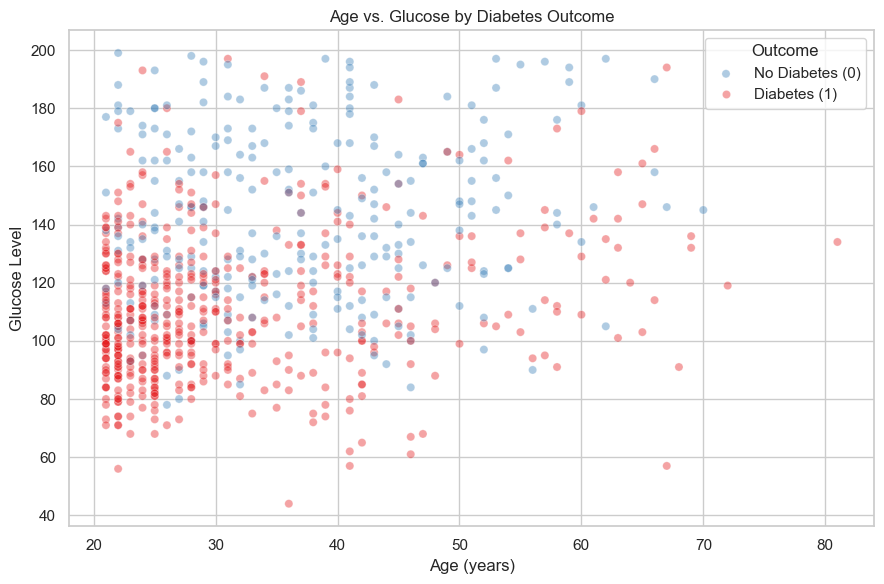

In [17]:
# Explore the relationship between age and glucose
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Glucose",
    hue="Outcome",
    hue_order=[0, 1],
    alpha=0.4,      # Slight transparency to reduce overlap
    s=35,
    palette="Set1"
)

plt.title("Age vs. Glucose by Diabetes Outcome")
plt.xlabel("Age (years)")
plt.ylabel("Glucose Level")
plt.legend(title="Outcome", labels=["No Diabetes (0)", "Diabetes (1)"])
plt.tight_layout()
plt.show()


### Interpretation of Scatter Plot

- Individuals with diabetes (Outcome = 1) tend to show higher glucose levels overall, although the two groups overlap considerably.
- Age alone does not clearly separate individuals with and without diabetes in this dataset.
- Glucose appears to show a clearer association with diabetes status than age in this visualization. However, its relative predictive importance should be evaluated using model performance and feature analysis.

---

### 6.5 Box plot of BMI

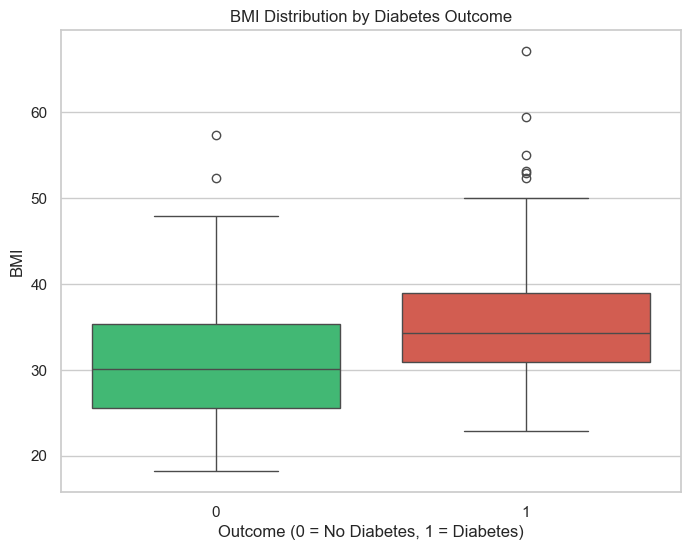

In [14]:
# Boxplot of BMI by diabetes status
plt.figure(figsize=(8, 6))
sns.boxplot(
    x='Outcome',
    y='BMI',
    data=df,
    hue='Outcome',
    palette=['#2ecc71', '#e74c3c'],
    legend=False)
plt.title('BMI Distribution by Diabetes Outcome')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('BMI')
plt.show()

### Interpretation of BMI Distribution

- The median BMI is higher in the Outcome = 1 group than in the Outcome = 0 group.
-  The distributions overlap, and both groups contain observations with relatively high BMI values.
- This suggests an association between BMI and diabetes status in this dataset.
-  The boxplot alone cannot establish causation or determine BMI's independent predictive value.
  
---

### 6.6 Probability of Diabetes by Number of Pregnancies - Bar Plot

,Pregnancies,Observed_Rate,Sample_Size
0,0,0.342342,111
1,1,0.214815,135
2,2,0.184466,103
3,3,0.360000,75
4,4,0.338235,68
5,5,0.368421,57
6,6,0.320000,50
7,7,0.555556,45
8,8,0.578947,38
9,9,0.642857,28


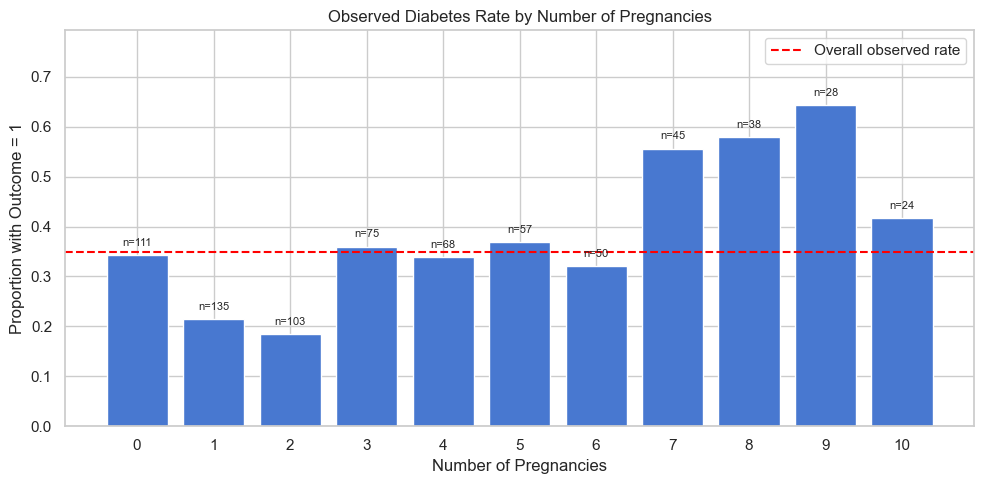

In [18]:
# Estimate the observed positive-outcome rate by pregnancy count
pregnancy_summary = (
    df.groupby("Pregnancies")["Outcome"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={
        "mean": "Observed_Rate",
        "count": "Sample_Size"
    })
)

# Exclude groups with fewer than 15 observations from the plot
reliable_groups = pregnancy_summary[
    pregnancy_summary["Sample_Size"] >= 15
].copy()

display(pregnancy_summary)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    reliable_groups["Pregnancies"].astype(str),
    reliable_groups["Observed_Rate"]
)

# Display the sample size above each bar
for bar, n in zip(bars, reliable_groups["Sample_Size"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"n={n}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.axhline(               
    df["Outcome"].mean(),
    color="red",
    linestyle="--",
    label="Overall observed rate"
)

plt.title("Observed Diabetes Rate by Number of Pregnancies")
plt.xlabel("Number of Pregnancies")
plt.ylabel("Proportion with Outcome = 1")
plt.ylim(0, min(1.15, reliable_groups["Observed_Rate"].max() + 0.15))
plt.legend()
plt.tight_layout()
plt.show()



### Interpretation of Observed Diabetes Rates

- The observed proportion of Outcome = 1 varies across pregnancy-count groups.
- Some groups have higher observed rates than the overall dataset average, but these differences should be interpreted alongside each group's sample size.
- Groups with few observations can produce extreme rates that are unstable and should not be generalized to a wider population.
- The chart describes patterns in this dataset; it does not establish that a higher pregnancy count causes diabetes.

---


## 7. Data Splitting & Scaling
### Train/Test Split & Pipeline‑Based Preprocessing



1. Separate features and target
2. Split data into train/test sets
3. Scale features for better model performance


### 7.1 Train/Test Split

In [22]:
# Separate input features and target variable
X = df.drop(columns='Outcome')
y = df['Outcome']

# Split the data into training and testing sets
# Stratification preserves the original class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Verify class proportions in both datasets
print("Training set class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest set class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Training set class proportions:
Outcome
0    0.652
1    0.348
Name: proportion, dtype: float64

Test set class proportions:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


- The dataset was `split into 70% training data and 30% testing data`.
- Stratified sampling maintained similar outcome proportions across both sets.
- The training set is used to fit the models, while the test set is reserved for final evaluation.
- A fixed random state ensures reproducible results.


---

### 7.2 Pipelines for Data Preprocessing and Model Training


In [23]:
# Pipeline for Logistic Regression
# Imputation + Scaling + Model
lr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('lr', LogisticRegression(random_state=42, max_iter=1000))
])

# Pipeline for Random Forest
# Imputation + Model
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('rf', RandomForestClassifier(random_state=42))
])


### Why Use Pipelines?

- Pipelines `combine preprocessing and model training into a single workflow`.
- The `median imputer` learns replacement values from the training data.
- `RobustScaler` reduces the influence of extreme values on feature scaling.
- `Logistic Regression uses scaling` because it is sensitive to feature magnitudes.
- 1Random Forest does not require feature scaling1 because it uses tree-based splits.
- Keeping preprocessing inside each pipeline helps `prevent data leakage` during training and cross-validation.

---

## 8. Model Training & Evaluation

### 8.1 Function to Evaluate Classification Models

In [21]:
# Function to print classification report
def evaluate_model(model_name, y_test, y_pred):

    accuracy = accuracy_score(y_test, y_pred)

    print(f"\nModel: {model_name}")
    print(f"Accuracy: {accuracy:.4f}\n")

    print("Classification Report")
    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Diabetes', 'Diabetes']
    ))

    return accuracy


- This function is used to evaluate the performance of classification models.
- It calculates the model accuracy, prints a detailed classification report.
- The function computes the accuracy score, which shows the overall percentage of correct predictions made by the model.
- It prints the classification report, which includes precision, recall, and F1-score for each class.These metrics provide a more detailed view of the model’s performance for predicting diabetic and non‑diabetic cases.
---

### 8.2 Random Forest with Pipeline


* Training model
* Preddiction
* Evaluation

In [19]:
# Train the pipeline (includes imputation + model training)
rf_pipeline.fit(X_train, y_train)

# Predict using the trained pipeline
rf_pred = rf_pipeline.predict(X_test)

# Evaluate the model
rf_accuracy = evaluate_model("Random Forest", y_test, rf_pred)




Model: Random Forest
Accuracy: 0.7489

Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.78      0.86      0.82       150
    Diabetes       0.68      0.54      0.60        81

    accuracy                           0.75       231
   macro avg       0.73      0.70      0.71       231
weighted avg       0.74      0.75      0.74       231



### 8.3 Logistic Regression with Pipeline


* Training model
* Preddiction
* Evaluation

In [20]:
# Train the pipeline (includes imputation + scaling + model training)
lr_pipeline.fit(X_train, y_train)

# Predict using the trained pipeline
lr_pred = lr_pipeline.predict(X_test)

# Evaluate the model
lr_accuracy = evaluate_model("Logistic Regression", y_test, lr_pred)



Model: Logistic Regression
Accuracy: 0.7446

Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.77      0.86      0.81       150
    Diabetes       0.67      0.53      0.59        81

    accuracy                           0.74       231
   macro avg       0.72      0.70      0.70       231
weighted avg       0.74      0.74      0.74       231



---

### 8.4 Confusion Matrix

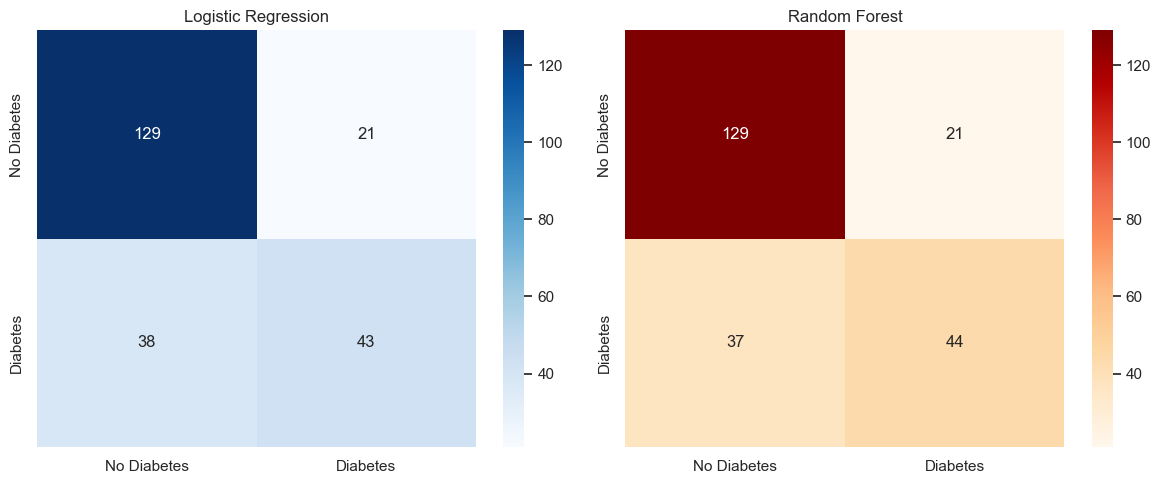

In [21]:
# Create two plots side by side to compare the models
fig, axes = plt.subplots(1, 2, figsize=(12,5))


# Compute confusion matrix for Logistic Regression predictions
cm_lr = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes','Diabetes'],   # Predicted labels
            yticklabels=['No Diabetes','Diabetes'],   # Actual labels
            ax=axes[0])

axes[0].set_title("Logistic Regression")




# Compute confusion matrix for Random Forest predictions
cm_rf = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='OrRd',
            xticklabels=['No Diabetes','Diabetes'],   # Predicted labels
            yticklabels=['No Diabetes','Diabetes'],   # Actual labels
            ax=axes[1])

axes[1].set_title("Random Forest")


plt.tight_layout()
plt.show()


- Confusion Matrix is used to evaluate classification models by showing the number of correct and incorrect predictions. 
- It helps understand how well the model distinguishes between diabetic and non‑diabetic cases by displaying True Positives, True Negatives, False Positives, and False Negatives.

- Both models show similar performance in the confusion matrices.
- Logistic Regression correctly identified 43 diabetic patients, while Random Forest identified 44. 
- Random Forest slightly reduced false negative predictions, meaning it missed fewer diabetic cases, which is important in medical prediction tasks.

---

### 8.5 ROC Curve and AUC Analysis

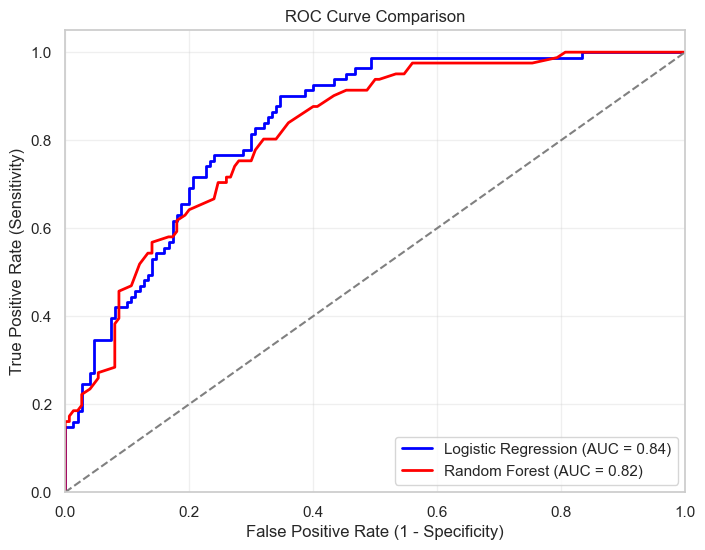

In [22]:
from sklearn.metrics import roc_curve, auc

# Get prediction probabilities for the positive class (Diabetes)
# predict_proba returns probabilities for both classes, so we select column 1 (positive class)
lr_probs = lr_pipeline.predict_proba(X_test)[:, 1]
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]


#Calculate False Positive Rate (FPR) and True Positive Rate (TPR) for Logistic Regression to draw the ROC curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)


# Compute the Area Under the Curve (AUC)
roc_auc_lr = auc(fpr_lr, tpr_lr)


# Compute the Area Under the Curve (AUC)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

# Calculate AUC score for Random Forest
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(8, 6))

# Plot ROC curve for Logistic Regression
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, label=f'Logistic Regression (AUC = {roc_auc_lr:.2f})')

# Plot ROC curve for Random Forest
plt.plot(fpr_rf, tpr_rf, color='red', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.2f})')

# Plot a diagonal dashed line which represents a random classifier
# Any useful model should perform above this line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.xlim([0.0, 1.0])      # Define the limits of the x-axis
plt.ylim([0.0, 1.05])     # Define the limits of the y-axis

plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve Comparison')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)       # Add a light grid to improve readability of the plot

plt.show()


- The ROC curve shows how well the model separates diabetic and non-diabetic cases.
- The x-axis (False Positive Rate) represents wrong positive predictions, and the y-axis (True Positive Rate) shows correctly predicted positives.
- Each point corresponds to a different decision threshold.
- The AUC (Area Under the Curve) summarizes the model performance:


### Interpretation of This Plot
- Both models perform well, as their curves lie above the random line.
- Logistic Regression (AUC = 0.84) slightly outperforms Random Forest (AUC = 0.82).
- Overall, both demonstrate good ability to distinguish diabetic from non-diabetic patients.




---

### 8.6 Model Performance Comparison

Create a table to compare the performance of Logistic Regression and Random Forest using common classification metrics

In [23]:
comparison = pd.DataFrame({

    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, rf_pred)
    ]

})

comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.744589,0.671875,0.530864,0.593103
1,Random Forest,0.748918,0.676923,0.543210,0.602740


Based on the comparison table:

- Random Forest achieved slightly higher accuracy (74.8%) and F1 score (60.2%), suggesting it performs slightly better on this dataset. However, the difference between the two models is relatively small.

- The results of both models are quite similar, which may indicate that the relationship between the features and the target variable can be captured reasonably well by both a linear model and a tree-based model.

- Both models show relatively low Recall (around 53–54%). This means that nearly half of the actual diabetes cases are not correctly identified. In a medical context, this is an important limitation, since missing a potential diagnosis can have serious consequences.

- Overall, while Random Forest performs slightly better, both models still have room for improvement, particularly in identifying more positive diabetes cases (improving Recall).
---

## 9. Most Important Features in Diabetes Prediction (using Random Forest)


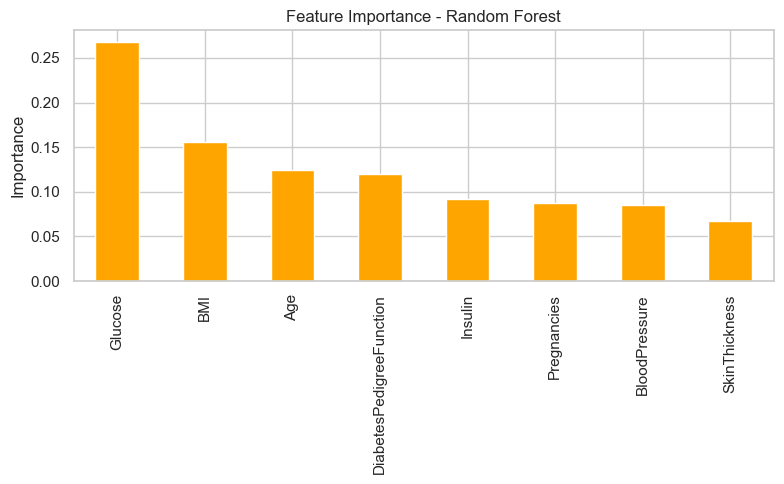

Top features:
Glucose                     0.267455
BMI                         0.155972
Age                         0.124982
DiabetesPedigreeFunction    0.119556
Insulin                     0.091711
Pregnancies                 0.087162
BloodPressure               0.085607
SkinThickness               0.067557
dtype: float64


In [28]:
# Get the trained Random Forest model from pipeline
rf_model = rf_pipeline.named_steps["rf"]

# Extract feature importance
importances = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

# Plot feature importance
plt.figure(figsize=(8,5))
importances.plot(kind="bar", color="orange")

plt.title("Feature Importance - Random Forest")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

print("Top features:")
print(importances.head(8))


- The plot shows the most influential features used by the Random Forest model for diabetes prediction.
- Glucose and BMI had the highest impact on the model’s decisions.

--------------------------

## 10. Cross Validation

- To better evaluate the models, 5-fold cross-validation was applied to the training data.
- In this method, the training dataset is divided into five parts. In each iteration, four parts are used for training and one part is used for validation.
- This process is repeated five times so that each part of the data is used once for validation.
- Cross-validation helps provide a more reliable estimate of model performance and reduces the chance that the results depend on a single train-test split.
- By comparing the cross-validation scores of Logistic Regression and Random Forest, we can see which model performs more consistently across different subsets of the data

### 10.1 Perform Cross-Validation on Logistic Regression Pipeline

In [24]:
cv_scores_lr = cross_val_score(lr_pipeline, X_train, y_train, cv=5, scoring="accuracy")

print("Logistic Regression Cross Validation Scores:", cv_scores_lr)
print("Mean CV Accuracy:", np.mean(cv_scores_lr))


Logistic Regression Cross Validation Scores: [0.80555556 0.78703704 0.79439252 0.79439252 0.71028037]
Mean CV Accuracy: 0.7783316026306681


### 10.2 Perform Cross-Validation on Random Forest Pipeline

In [25]:
# Perform cross-validation on Random Forest pipeline
cv_scores_rf = cross_val_score(rf_pipeline, X_train, y_train, cv=5, scoring="accuracy")

print("Random Forest Cross Validation Scores:", cv_scores_rf)
print("Mean CV Accuracy:", np.mean(cv_scores_rf))


Random Forest Cross Validation Scores: [0.75       0.75       0.76635514 0.75700935 0.78504673]
Mean CV Accuracy: 0.7616822429906542


### Cross-Validation Results
- The results of the 5-fold cross-validation show that both models achieve relatively consistent performance across different splits of the training data.
- Logistic Regression achieved a mean cross-validation accuracy of approximately 0.78, while Random Forest achieved a mean accuracy of about 0.76. 
- This suggests that Logistic Regression performs slightly better on average during cross-validation.
- Both models demonstrate reasonable generalization ability, with Logistic Regression showing a small advantage in cross-validation performance.
---

## 11. Final Comparison of Models

- To evaluate the performance of Logistic Regression and Random Forest, several metrics were used, including accuracy, F1-score, confusion matrices, ROC-AUC, and cross-validation.
- The results show that Random Forest achieved slightly higher accuracy and F1-score than Logistic Regression. 
- However, Logistic Regression obtained a higher ROC-AUC score and slightly better cross-validation results.
- The confusion matrices show that both models correctly identify many non-diabetic patients, but they still miss a number of actual diabetes cases. This means the recall for diabetic patients is relatively low.
- Overall, the performance of the two models is very similar.
- Random Forest performs slightly better in accuracy, while Logistic Regression shows better ROC-AUC and more stable cross-validation results.

These results suggest that both models have limitations in detecting all positive diabetes cases.
Improving recall would be an important goal for future work.


---


## 12. Conclusion
- This project explored the use of machine learning models to predict diabetes based on patient health indicators.
- Two models were implemented: Logistic Regression and Random Forest. Both models showed similar performance, although Random Forest achieved slightly better results in terms of accuracy and F1-score.
- The evaluation using confusion matrices, ROC curves, and classification metrics helped provide a clearer understanding of how the models perform. 
- Overall, the models demonstrate that machine learning can be useful for identifying potential diabetes risk, although the results also show that prediction accuracy is still limited.

---

## 13. Summary
- In this project, a diabetes dataset was analyzed and prepared using preprocessing techniques such as handling missing values and feature scaling. 
- Two classification models were trained and evaluated: Logistic Regression and Random Forest. 
- Their performance was compared using several metrics including accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices. The results showed that Random Forest performed slightly better, but both models produced comparable outcomes
---

## 14. Limitations
- One limitation of this project is that the dataset is relatively small and may not fully represent the diversity of real patient populations.
- In addition, the models show relatively low recall, meaning that some diabetes cases are not correctly identified. 
- Another limitation is that only two machine learning models were tested and no advanced techniques such as hyperparameter tuning or class balancing were applied. 
- Because of these limitations, the models should not be considered reliable for real medical decision-making.
---

## 15. Medical Explanation
- Diabetes is a chronic condition that affects how the body processes blood glucose. 
- Early detection is important because untreated diabetes can lead to serious complications such as heart disease, kidney damage, and nerve problems. 
- Machine learning models can help analyze patterns in patient data and identify individuals who may be at higher risk. 
- However, these models are meant to support medical professionals rather than replace clinical diagnosis.
---

## 16. Future Work
- Future improvements could include testing additional machine learning models such as Gradient Boosting or Support Vector Machines. 
- Applying hyperparameter tuning could also improve model performance. 
- Another important improvement would be handling class imbalance or collecting larger and more diverse datasets. 
- In addition, more advanced evaluation techniques could be used to better understand how the models generalize to new data.
---

## References

- UCI Machine Learning Repository – Pima Indians Diabetes Dataset  
https://archive.ics.uci.edu/ml/datasets/pima+indians+diabetes

- Scikit-learn Documentation  
https://scikit-learn.org/stable/

- World Health Organization (WHO) – Diabetes Overview  
https://www.who.int/health-topics/diabetes

- American Diabetes Association – Diabetes Information  
https://diabetes.org/about-diabetes


---
